# Hyperparameter stability near the tuned contamination scenarios

This experiment evaluates each scenario's frozen optimal $L_p$ exponent, smoothing parameter, and solver tolerance on nearby contamination conditions. The contamination fraction varies by $\pm 10\%$ relative to its anchor value, and the outlier magnitude varies by factors of 0.8, 1.0, and 1.2. Each fit is evaluated on an independent clean test set and compared with OLS. Results are saved per fit to `results/hyperparameter_stability.csv`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
while not (project_root / "Experiments" / "hyperparameter_stability.py").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import Experiments.plot_hyperparameter_stability as stability_plot
from Experiments.hyperparameter_stability import (
    read_frozen_parameters,
    run_experiment,
    write_results_csv,
)

parameters_path = project_root / "results" / "tolerance_tuning.csv"
output_path = project_root / "results" / "hyperparameter_stability.csv"
plot_hyperparameter_stability = stability_plot.plot_hyperparameter_stability
scenarios = read_frozen_parameters(parameters_path)

parameter_table = pd.DataFrame(
    [
        {
            "scenario": scenario.name,
            "anchor c": scenario.proportion,
            "anchor A": scenario.magnitude,
            "lp": scenario.lp,
            "eps": scenario.eps,
            "tolerance": scenario.tolerance,
        }
        for scenario in scenarios
    ]
)
display(parameter_table)

,scenario,anchor c,anchor A,lp,eps,tolerance
0,scenario_1,0.02,0.1,0.712744,0.012147,0.000025
1,scenario_2,0.10,0.5,0.650488,0.011419,0.001585
2,scenario_3,0.25,5.0,0.462744,0.020146,0.000398


## Run the paired Monte Carlo experiment

The default run uses 1,000 repetitions per target condition, 1,000 training observations, and a separate clean test set of 1,000 observations. This runs 54,000 model fits in total.

In [2]:
experiments = 1000
start_time = time.perf_counter()
experiment_rows = run_experiment(
    scenarios,
    experiments=experiments,
    seed=42,
    proportion_shift_fraction=0.10,
    magnitude_multipliers=(0.8, 1.0, 1.2),
    n_train=1000,
    n_test=1000,
    beta=(1.0, 1.0),
    noise_std=0.01,
    maxiter=200,
)
write_results_csv(experiment_rows, output_path)
elapsed_seconds = time.perf_counter() - start_time
results = pd.DataFrame(experiment_rows)

print(f"Saved {len(results):,} per-fit results to {output_path}")
print(f"Monte Carlo repetitions per target condition: {experiments:,}")
print(f"Elapsed time: {elapsed_seconds:.1f} seconds")

Saved 54,000 per-fit results to /Users/pabloortizbadenes/Desktop/Misc/Proyectos/nonconvex_regression/results/hyperparameter_stability.csv
Monte Carlo repetitions per target condition: 1,000
Elapsed time: 15.8 seconds


In [3]:
overall_summary = (
    results.groupby(["anchor_scenario", "method"])["clean_test_rmse"]
    .agg(mean="mean", standard_deviation="std", repetitions="count")
    .reset_index()
)
display(overall_summary)

,anchor_scenario,method,mean,standard_deviation,repetitions
0,scenario_1,Lp,0.010015,0.000221,9000
1,scenario_1,OLS,0.010035,0.000225,9000
2,scenario_2,Lp,0.010026,0.000222,9000
3,scenario_2,OLS,0.012176,0.002104,9000
4,scenario_3,Lp,0.010022,0.000222,9000
5,scenario_3,OLS,0.098683,0.055211,9000


## Results across the local contamination neighborhoods

The heatmaps show each method's clean-test RMSE and the paired mean difference $\mathrm{RMSE}_{L_p}-\mathrm{RMSE}_{OLS}$ (negative values favor $L_p$). Trend plots show mean RMSE with standard-error bars.

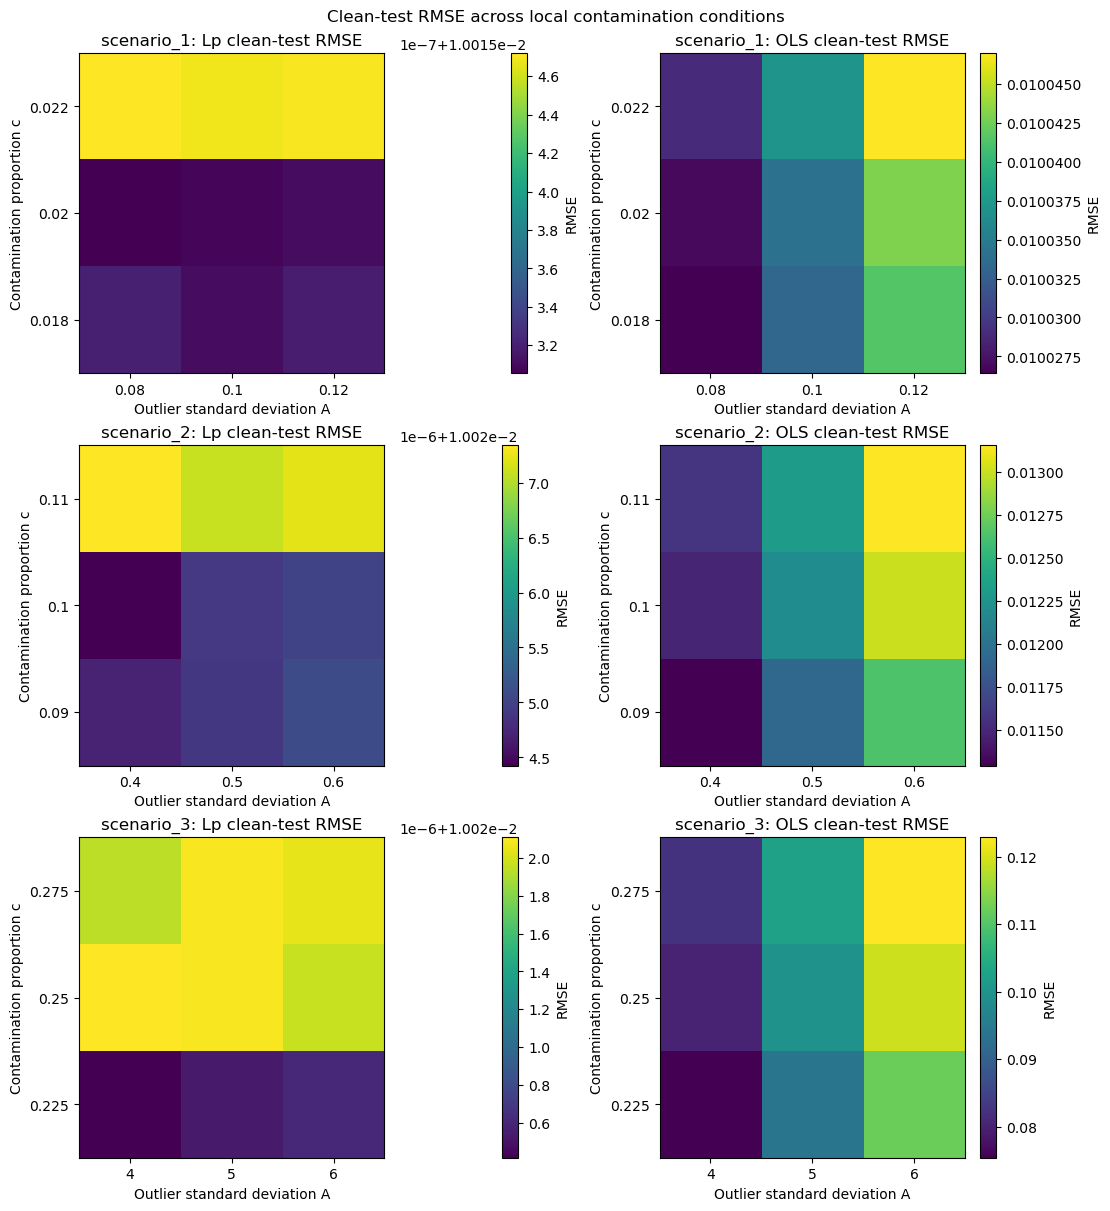

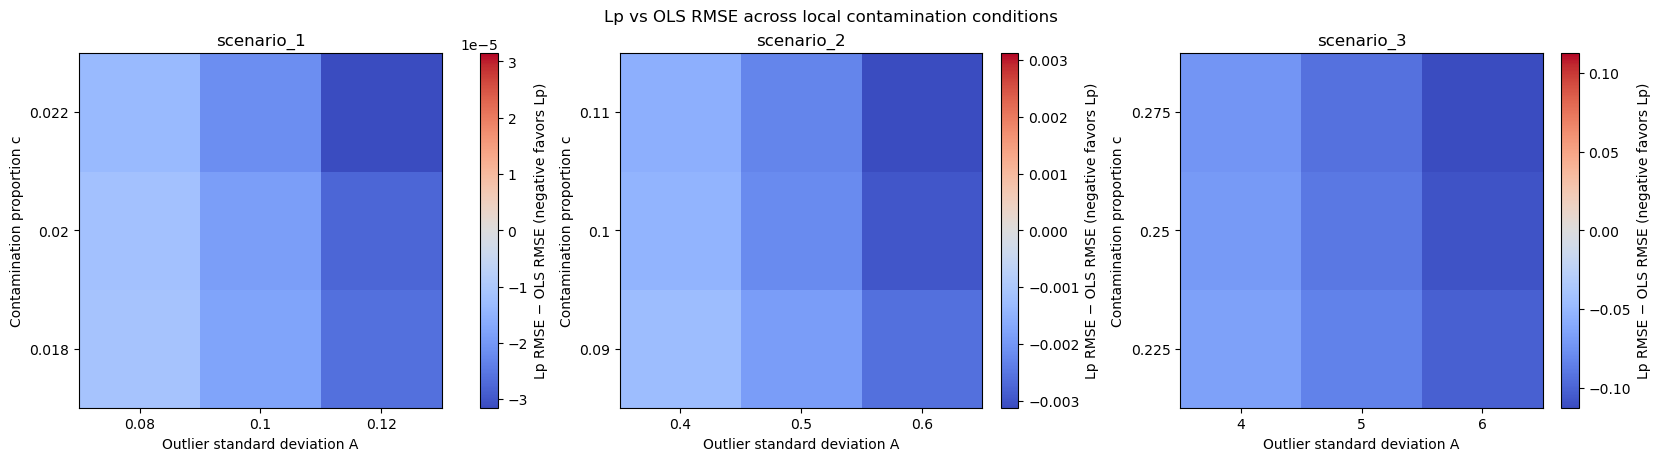

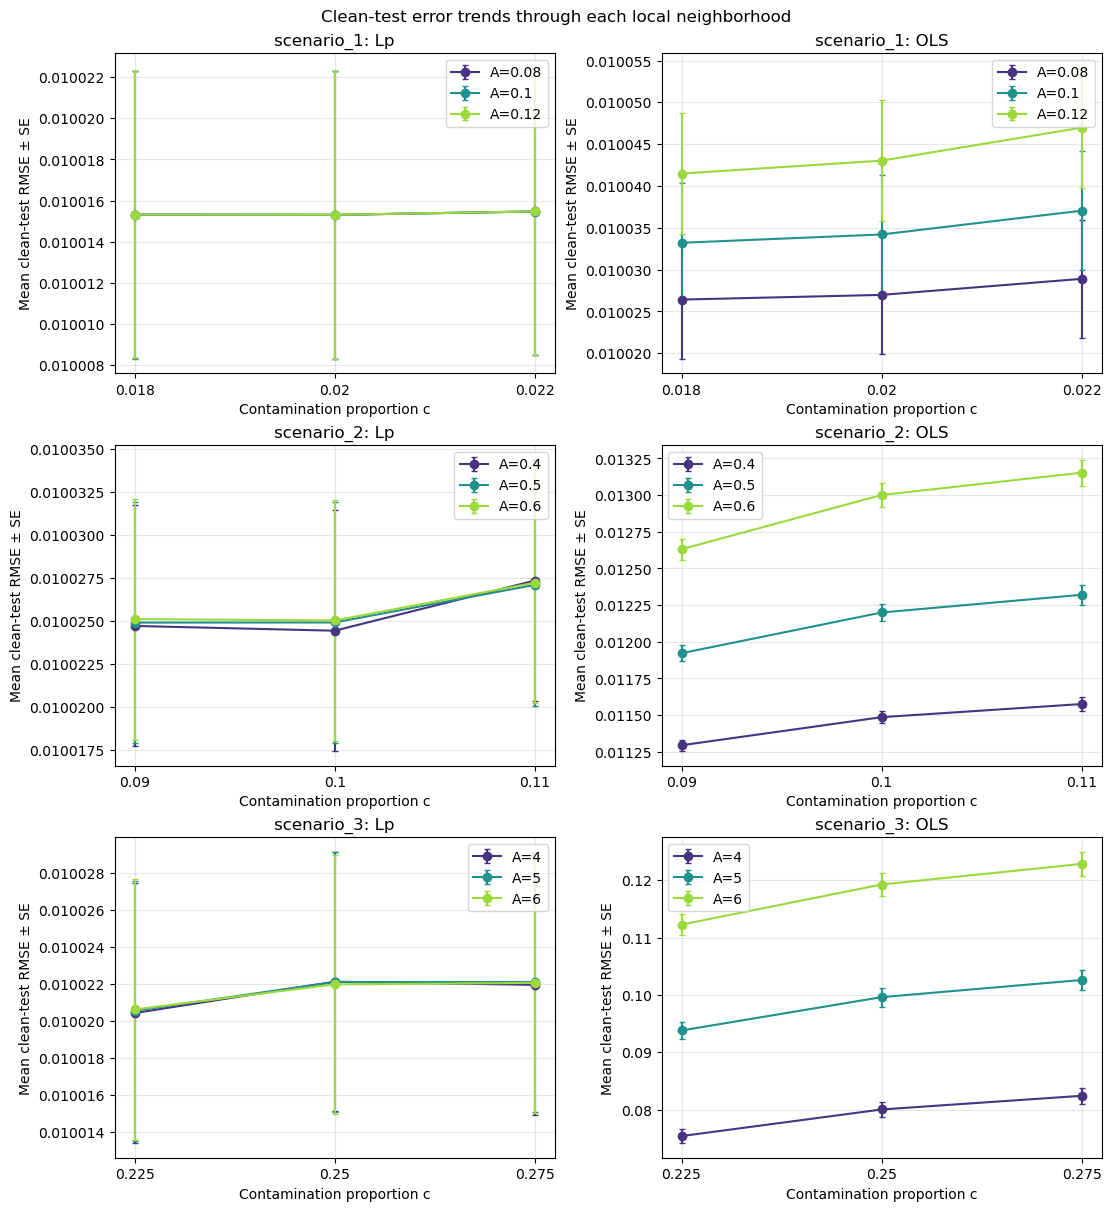

In [4]:
figures = plot_hyperparameter_stability(output_path)
for figure in figures:
    display(figure)
    plt.close(figure)

## IRLS iteration and RMSE distributions

The plots below use the saved Lp (IRLS) fits and show distributions separately for each anchor scenario. Iteration counts are discrete; RMSE is measured on the clean test set.

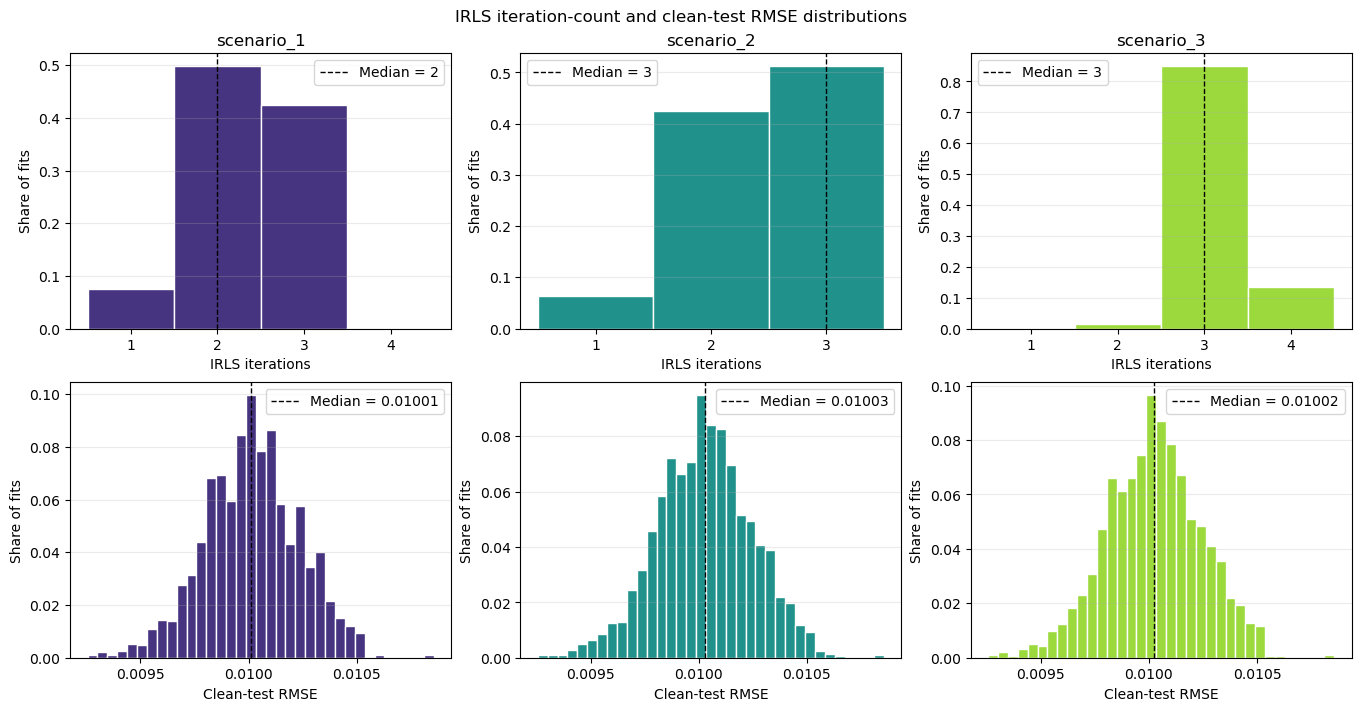

In [2]:
import numpy as np
from matplotlib.ticker import MaxNLocator

distribution_results = pd.read_csv(output_path)
irls_results = distribution_results.loc[distribution_results["method"] == "Lp"].copy()
if irls_results.empty:
    raise ValueError(f"No IRLS results found in {output_path}.")

scenario_names = sorted(irls_results["anchor_scenario"].unique())
rmse_bins = np.linspace(
    irls_results["clean_test_rmse"].min(),
    irls_results["clean_test_rmse"].max(),
    36,
)
figure, axes = plt.subplots(
    2,
    len(scenario_names),
    figsize=(4.5 * len(scenario_names), 7),
    squeeze=False,
    layout="constrained",
)
colors = plt.get_cmap("viridis")(np.linspace(0.15, 0.85, len(scenario_names)))

for column, (scenario, color) in enumerate(zip(scenario_names, colors, strict=True)):
    scenario_results = irls_results.loc[irls_results["anchor_scenario"] == scenario]
    iterations = scenario_results["iterations"].astype(int)
    iteration_bins = np.arange(iterations.min() - 0.5, iterations.max() + 1.5)
    iteration_axis = axes[0, column]
    iteration_axis.hist(
        iterations,
        bins=iteration_bins,
        weights=np.full(len(iterations), 1 / len(iterations)),
        color=color,
        edgecolor="white",
    )
    iteration_axis.axvline(
        iterations.median(),
        color="black",
        linestyle="--",
        linewidth=1,
        label=f"Median = {iterations.median():g}",
    )
    iteration_axis.set_xticks(sorted(iterations.unique()))
    iteration_axis.set_title(scenario)
    iteration_axis.set_xlabel("IRLS iterations")
    iteration_axis.set_ylabel("Share of fits")
    iteration_axis.legend()
    iteration_axis.grid(axis="y", alpha=0.25)

    rmse = scenario_results["clean_test_rmse"]
    rmse_axis = axes[1, column]
    rmse_axis.hist(
        rmse,
        bins=rmse_bins,
        weights=np.full(len(rmse), 1 / len(rmse)),
        color=color,
        edgecolor="white",
    )
    rmse_axis.axvline(
        rmse.median(),
        color="black",
        linestyle="--",
        linewidth=1,
        label=f"Median = {rmse.median():.5f}",
    )
    rmse_axis.set_xlabel("Clean-test RMSE")
    rmse_axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    rmse_axis.set_ylabel("Share of fits")
    rmse_axis.legend()
    rmse_axis.grid(axis="y", alpha=0.25)

figure.suptitle("IRLS iteration-count and clean-test RMSE distributions")
plt.show()